# Predicting Stock Price Direction from Market Micro-Movements and Macroeconomics
### Capstone — Initial Report, Exploratory Data Analysis and Baseline Model

**Research question.** Can daily price/volume behaviour (technical indicators such as EMA, RSI and MACD) combined with
macroeconomic conditions (Treasury yields, yield-curve spread, VIX, Fed funds, inflation, unemployment) predict the
**direction of the next day's return**? And can those predictions drive a trading strategy that earns a good
risk-adjusted return while **avoiding severe drawdowns**?

**Why it matters.** A forecaster that is right even slightly more than half the time can be valuable *if* it also keeps
the portfolio out of the market during stress periods. The full project will use a Temporal Fusion
Transformer for forecasting and a reinforcement-learning agent for execution. This notebook does the groundwork:

| Section | What it does |
|---|---|
| 1. Setup | Libraries, paths, configuration |
| 2. Data acquisition | Daily OHLCV from Yahoo Finance, macro series from FRED (cached to `data/raw/`) |
| 3. Data cleaning | Types, duplicates, missing values, publication-lag alignment of macro data |
| 4. Outlier analysis | Extreme returns, volume spikes, data-error checks |
| 5. Feature engineering | Returns, EMA, MACD, RSI, Bollinger, volatility, macro changes, regimes, target |
| 6. Exploratory analysis | Trends, distributions, stationarity, volatility clustering, macro relationships |
| 7. Baseline model | Logistic regression for next-day direction vs. a naive baseline, with a simple backtest |
| 8. Findings & next steps | Summary and plan for Final Capstone Submission|

> **Data sources:** [Yahoo Finance](https://finance.yahoo.com) via `yfinance` (split/dividend-adjusted prices) and
> [FRED](https://fred.stlouisfed.org) (Federal Reserve Bank of St. Louis). News-headline sentiment (FinBERT) is
> planned for final release and is not part of this baseline.

## 1. Setup

In [1]:
# Import all required libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 13, 'axes.labelsize': 11})
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.4f}'.format)

In [2]:
# Paths (works whether the notebook is run from the repo root or from notebooks/) This is for automation
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
IMG_DIR = PROJECT_ROOT / 'images'
RESULTS_DIR = PROJECT_ROOT / 'results'
for folder in (DATA_RAW, DATA_PROCESSED, IMG_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Include all the stocks need to be analyzed
TICKERS = {
    'SPY': 'Broad Market ETF',
    'AAPL': 'Technology',
    'MSFT': 'Technology',
    'JPM': 'Financials',
    'XOM': 'Energy',
    'JNJ': 'Health Care',
}
PRICE_START, PRICE_END = '2010-01-01', '2025-12-31'
MACRO_START = '2008-01-01'   # earlier start so 12-month inflation change is available from 2010

# FRED macro series
FRED_SERIES = {
    'DGS10': '10-Year Treasury yield (%)',
    'DGS2': '2-Year Treasury yield (%)',
    'T10Y2Y': '10Y minus 2Y spread (pp)',
    'VIXCLS': 'CBOE VIX index',
    'FEDFUNDS': 'Effective Fed funds rate (%)',
    'CPIAUCSL': 'CPI, all urban consumers (index)',
    'UNRATE': 'Unemployment rate (%)',
}
MONTHLY_SERIES = ['FEDFUNDS', 'CPIAUCSL', 'UNRATE']
DAILY_SERIES = [s for s in FRED_SERIES if s not in MONTHLY_SERIES]

SPLIT_DATE = pd.Timestamp('2022-01-01')   # train: 2010-2021, test: 2022 onwards (includes the 2022 bear market)
TRANSACTION_COST = 0.0005                 # 5 bps per position change (commission + slippage)
RANDOM_STATE = 42


def save_fig(name):
    """Save the current matplotlib figure to images/ for use in the README."""
    plt.savefig(IMG_DIR / f'{name}.png', dpi=110, bbox_inches='tight')

## 2. Data Acquisition

Both loaders download once and cache to `data/raw/`, so re-running the notebook is fast and reproducible.
Delete the CSVs to refresh the data.

In [3]:
def load_prices(tickers, start, end, cache=DATA_RAW / 'prices.csv'):
    """Daily split/dividend-adjusted OHLCV from Yahoo Finance in long format (one row per Date x Ticker)."""
    if cache.exists():
        return pd.read_csv(cache, parse_dates=['Date'])
    import yfinance as yf
    frames = []
    for ticker in tickers:
        data = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
        # newer yfinance returns (field, ticker) columns
        if isinstance(data.columns, pd.MultiIndex):          
            data.columns = data.columns.get_level_values(0)
        data = data.reset_index()[['Date', 'Open', 'High', 'Low', 'Close', 'Volume']]
        data['Ticker'] = ticker
        frames.append(data)
    prices = pd.concat(frames, ignore_index=True)
    prices.to_csv(cache, index=False)
    return prices


def load_fred(series_ids, start, end, cache=DATA_RAW / 'macro_fred.csv'):
    """Download FRED series via the public CSV endpoint (no API key) and outer-join them on date."""
    if cache.exists():
        return pd.read_csv(cache, parse_dates=['date'])
    frames = []
    for series in series_ids:
        url = f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}&cosd={start}&coed={end}'
        data = pd.read_csv(url)
        data.columns = ['date', series]
        data['date'] = pd.to_datetime(data['date'])
        # FRED marks missing values with '.'
        data[series] = pd.to_numeric(data[series], errors='coerce')   
        frames.append(data.set_index('date'))
    macro = pd.concat(frames, axis=1).sort_index().reset_index()
    macro.to_csv(cache, index=False)
    return macro


prices_raw = load_prices(TICKERS, PRICE_START, PRICE_END)
macro_raw = load_fred(FRED_SERIES, MACRO_START, PRICE_END)
print(f'Prices: {prices_raw.shape[0]:,} rows x {prices_raw.shape[1]} cols | '
      f'{prices_raw.Date.min():%Y-%m-%d} to {prices_raw.Date.max():%Y-%m-%d}')
print(f'Macro : {macro_raw.shape[0]:,} rows x {macro_raw.shape[1]} cols | '
      f'{macro_raw.date.min():%Y-%m-%d} to {macro_raw.date.max():%Y-%m-%d}')

Prices: 24,138 rows x 7 cols | 2010-01-04 to 2025-12-30
Macro : 4,758 rows x 8 cols | 2008-01-01 to 2025-12-31


**Using the automated pipeline's database.** If the daily pipeline (`python -m src.pipeline`) has populated
`db/market.db`, the next cell loads the data from there instead, so the analysis always uses the latest stored data.

In [4]:
DB_PATH = PROJECT_ROOT / 'db' / 'market.db'
if DB_PATH.exists():
    import sqlite3
    with sqlite3.connect(DB_PATH) as con:
        db_prices = pd.read_sql('SELECT * FROM prices', con, parse_dates=['date'])
        db_macro = pd.read_sql('SELECT date, series_id, value FROM macro', con, parse_dates=['date'])
    factor = db_prices['adj_close'] / db_prices['close']          # dividend/split adjustment
    prices_raw = pd.DataFrame({'Date': db_prices['date'], 'Open': db_prices['open'] * factor,
                               'High': db_prices['high'] * factor, 'Low': db_prices['low'] * factor,
                               'Close': db_prices['adj_close'], 'Volume': db_prices['volume'],
                               'Ticker': db_prices['ticker']})
    macro_raw = db_macro.pivot(index='date', columns='series_id', values='value').reset_index()
    macro_raw.columns.name = None
    print(f'Loaded from pipeline database: {len(prices_raw):,} price rows, latest {prices_raw.Date.max():%Y-%m-%d}')
else:
    print('No pipeline database found - using the CSV cache / direct download above.')

Loaded from pipeline database: 25,464 price rows, latest 2026-11-16


In [5]:
prices_raw.head()

,Date,Open,High,Low,Close,Volume,Ticker
0,2010-01-04,83.6543,84.4136,83.0141,84.3690,"118,944,600.0000",SPY
1,2010-01-05,84.3169,84.6295,84.0116,84.5923,"111,579,900.0000",SPY
2,2010-01-06,84.5104,84.8603,84.4434,84.6519,"116,074,400.0000",SPY
3,2010-01-07,84.4955,85.1134,84.2573,85.0092,"131,091,100.0000",SPY
4,2010-01-08,84.7859,85.3293,84.6147,85.2921,"126,402,800.0000",SPY


In [6]:
macro_raw.tail()

,date,CPIAUCSL,DGS10,DGS2,FEDFUNDS,T10Y2Y,UNRATE,VIXCLS
4984,2026-11-10,NaN,4.9800,4.7300,NaN,0.2500,NaN,19.4600
4985,2026-11-11,NaN,NaN,NaN,NaN,NaN,NaN,17.4900
4986,2026-11-12,NaN,5.1000,4.8600,NaN,0.2400,NaN,18.7000
4987,2026-11-13,NaN,5.1500,4.8800,NaN,0.2700,NaN,19.3000
4988,2026-11-16,NaN,NaN,NaN,NaN,0.2900,NaN,NaN


## 3. Data Cleaning

### 3.1 Price data — types, duplicates, missing and invalid values

In [7]:
prices = prices_raw.copy()
prices['Date'] = pd.to_datetime(prices['Date']).astype('datetime64[ns]')
prices['Ticker'] = prices['Ticker'].astype('category')

n_dupes = prices.duplicated(subset=['Date', 'Ticker']).sum()
missing = prices.isna().sum()
invalid = ((prices[['Open', 'High', 'Low', 'Close']] <= 0).any(axis=1) | (prices['High'] < prices['Low'])).sum()
zero_volume = (prices['Volume'] == 0).sum()

print(f'Duplicate (Date, Ticker) rows : {n_dupes}')
print(f'Rows with invalid prices      : {invalid}')
print(f'Rows with zero volume         : {zero_volume}')
print('Missing values per column:')
print(missing[missing > 0] if missing.any() else '  none')

# Remove duplicates, rows without a close price and impossible price bars
prices = (prices.drop_duplicates(subset=['Date', 'Ticker'], keep='last')
                .dropna(subset=['Close'])
                .loc[lambda d: (d[['Open', 'High', 'Low', 'Close']] > 0).all(axis=1) & (d['High'] >= d['Low'])]
                .sort_values(['Ticker', 'Date'])
                .reset_index(drop=True))
prices['Sector'] = prices['Ticker'].map(TICKERS).astype('category')
print(f'\nClean price rows: {len(prices):,}')

Duplicate (Date, Ticker) rows : 0
Rows with invalid prices      : 0
Rows with zero volume         : 0
Missing values per column:
  none

Clean price rows: 25,464


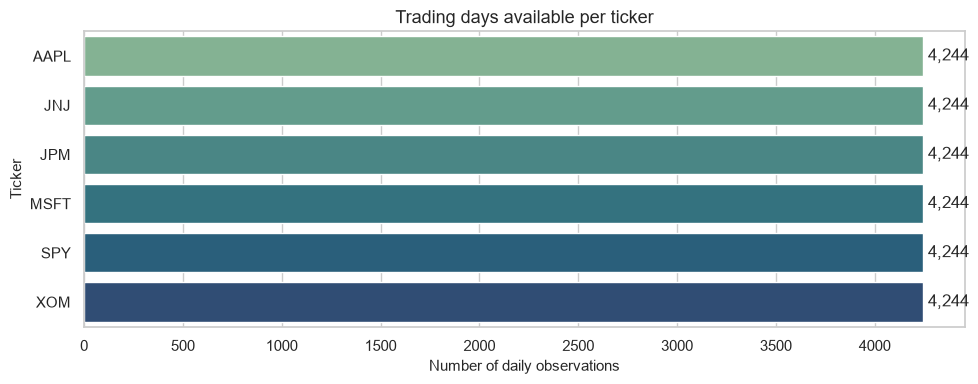

In [8]:
# Every ticker should have the same number of trading days; a gap would point to a download problem.
fig, ax = plt.subplots(figsize=(10, 4))
counts = prices.groupby('Ticker', observed=True).size().sort_values()
sns.barplot(x=counts.values, y=counts.index.astype(str), hue=counts.index.astype(str), palette='crest', legend=False, ax=ax)
ax.set(title='Trading days available per ticker', xlabel='Number of daily observations', ylabel='Ticker')
for i, v in enumerate(counts.values):
    ax.text(v, i, f' {v:,}', va='center')
plt.tight_layout(); save_fig('01_rows_per_ticker'); plt.show()

### 3.2 Macro data — missing values and look-ahead bias

FRED series come at different frequencies. After an outer join, daily series have gaps on bond-market holidays and the
monthly series are empty on every day except the first of the month. Imputation strategy:

* **Daily series** (yields, spread, VIX): forward-fill up to 5 days — the last published value is the best estimate on a
  holiday. FRED posts these values the next business day, so each is shifted forward one business day.
* **Monthly series** (Fed funds, CPI, unemployment): the value dated *1 March* is not published until mid-April.
  Using it on 1 March would leak future information, so each monthly value is only made **available one month and
  two weeks after its reference date**, then joined to trading days with an as-of (backward-looking) merge.

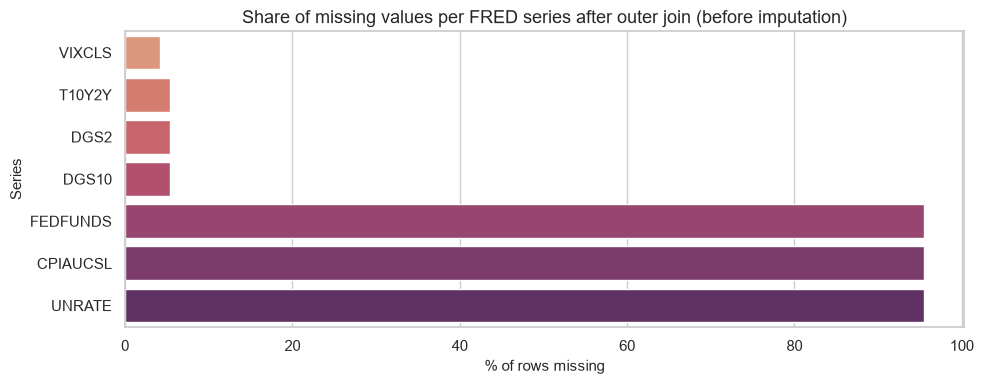

In [9]:
macro = macro_raw.copy()
macro['date'] = pd.to_datetime(macro['date']).astype('datetime64[ns]')
macro = macro.drop_duplicates(subset='date').sort_values('date')

# Missing-value profile before imputation
missing_pct = macro[list(FRED_SERIES)].isna().mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=missing_pct.values, y=missing_pct.index, hue=missing_pct.index, palette='flare', legend=False, ax=ax)
ax.set(title='Share of missing values per FRED series after outer join (before imputation)',
       xlabel='% of rows missing', ylabel='Series')
plt.tight_layout(); save_fig('02_macro_missing'); plt.show()

In [10]:
# Daily series: forward-fill short gaps, then add day-over-day changes
macro_daily = (macro[['date'] + DAILY_SERIES]
               .dropna(how='all', subset=DAILY_SERIES)
               .set_index('date')
               .ffill(limit=5))
macro_daily['DGS10_chg'] = macro_daily['DGS10'].diff()            # change in 10Y yield (pp)
macro_daily['T10Y2Y_chg'] = macro_daily['T10Y2Y'].diff()          # change in curve slope (pp)
macro_daily['VIX_chg'] = np.log(macro_daily['VIXCLS']).diff()     # % change in VIX (log)
# FRED publishes daily yields and the VIX close on the NEXT business day, so a value dated D is only usable from D+1
macro_daily.index = macro_daily.index + pd.offsets.BDay(1)

# Monthly series: derive inflation and shift to the date the market could actually know the number
macro_monthly = macro[['date'] + MONTHLY_SERIES].dropna(subset=MONTHLY_SERIES, how='all').copy()
macro_monthly['CPI_YoY'] = macro_monthly['CPIAUCSL'].pct_change(12, fill_method=None) * 100
macro_monthly['UNRATE_chg_3m'] = macro_monthly['UNRATE'].diff(3)
macro_monthly['available_date'] = macro_monthly['date'] + pd.DateOffset(months=1, days=14)
macro_monthly = macro_monthly.drop(columns=['date', 'CPIAUCSL']).rename(columns={'available_date': 'Date'})

# As-of merge: each trading day receives the latest macro value known on or before that day
df = pd.merge_asof(prices.sort_values('Date'),
                   macro_daily.reset_index().rename(columns={'date': 'Date'}),
                   on='Date', direction='backward')
df = pd.merge_asof(df, macro_monthly.sort_values('Date'), on='Date', direction='backward')
df = df.sort_values(['Ticker', 'Date']).reset_index(drop=True)

remaining = df.isna().sum()
print('Missing values after merge:')
print(remaining[remaining > 0] if remaining.any() else '  none')

Missing values after merge:
UNRATE           114
CPI_YoY          120
UNRATE_chg_3m    228
dtype: int64


## 4. Feature Engineering

All indicators are computed per ticker using only past and current data. Price-level indicators (EMA, MACD) are
converted to scale-free ratios so that a $500 stock and a $50 stock are comparable.

| Group | Features |
|---|---|
| Returns | 1-, 5- and 21-day log returns, lagged returns |
| Trend | Close vs EMA-12 / EMA-26, MACD and MACD histogram (scaled by price) |
| Momentum | RSI-14 |
| Volatility | 21-day realised volatility, Bollinger-band width and position, intraday high-low range |
| Volume | Volume z-score vs its 21-day average |
| Macro | Yield levels and changes, curve slope, VIX level/change, Fed funds, CPI YoY, unemployment change |
| Categorical | Ticker, sector, VIX regime, yield-curve inversion flag, day of week |
| Target | `target_up` = 1 if the next day's log return is positive (and `target_ret`, the return itself) |

In [11]:
def add_technical_features(group):
    """Technical indicators for a single ticker's time series (rows sorted by date)."""
    g = group.copy()
    close = g['Close']

    # Returns
    g['log_ret'] = np.log(close).diff()
    g['ret_5d'] = np.log(close / close.shift(5))
    g['ret_21d'] = np.log(close / close.shift(21))
    g['ret_lag1'] = g['log_ret'].shift(1)
    g['ret_lag2'] = g['log_ret'].shift(2)

    # Trend: EMA and MACD (scaled by price)
    ema_12 = close.ewm(span=12, adjust=False).mean()
    ema_26 = close.ewm(span=26, adjust=False).mean()
    macd = ema_12 - ema_26
    macd_signal = macd.ewm(span=9, adjust=False).mean()
    g['ema_12'], g['ema_26'] = ema_12, ema_26
    g['close_vs_ema12'] = close / ema_12 - 1
    g['close_vs_ema26'] = close / ema_26 - 1
    g['macd_norm'] = macd / close
    g['macd_hist_norm'] = (macd - macd_signal) / close

    # Momentum: Wilder's RSI-14
    delta = close.diff()
    avg_gain = delta.clip(lower=0).ewm(alpha=1 / 14, adjust=False).mean()
    avg_loss = (-delta.clip(upper=0)).ewm(alpha=1 / 14, adjust=False).mean()
    g['rsi_14'] = 100 - 100 / (1 + avg_gain / avg_loss)

    # Volatility
    sma_20, std_20 = close.rolling(20).mean(), close.rolling(20).std()
    #annualized
    g['vol_21d'] = g['log_ret'].rolling(21).std() * np.sqrt(252)
    g['bb_width'] = 4 * std_20 / sma_20
    # -1 lower band, +1 upper band
    g['bb_position'] = (close - sma_20) / (2 * std_20)               
    g['hl_range'] = (g['High'] - g['Low']) / close

    # Volume
    g['volume_z'] = (g['Volume'] - g['Volume'].rolling(21).mean()) / g['Volume'].rolling(21).std()

    # Targets: next trading day's return and its direction
    g['target_ret'] = g['log_ret'].shift(-1)
    g['target_up'] = (g['target_ret'] > 0).astype(float).where(g['target_ret'].notna())
    # for EDA only
    g['fwd_vol_21d'] = g['log_ret'][::-1].rolling(21).std()[::-1].shift(-1) * np.sqrt(252)
    return g


df = pd.concat([add_technical_features(g) for _, g in df.groupby('Ticker', observed=True)], ignore_index=True)

# Calendar and regime features (categorical)
df['day_of_week'] = df['Date'].dt.day_name().str[:3]
df['vix_regime'] = pd.cut(df['VIXCLS'], bins=[0, 15, 20, 30, np.inf],
                          labels=['Calm (<15)', 'Normal (15-20)', 'Elevated (20-30)', 'Stress (>30)'])
df['curve_inverted'] = np.where(df['T10Y2Y'] < 0, 'Inverted', 'Normal')

NUMERIC_FEATURES = ['log_ret', 'ret_5d', 'ret_21d', 'ret_lag1', 'ret_lag2',
                    'close_vs_ema12', 'close_vs_ema26', 'macd_norm', 'macd_hist_norm', 'rsi_14',
                    'vol_21d', 'bb_width', 'bb_position', 'hl_range', 'volume_z',
                    'DGS10', 'DGS10_chg', 'T10Y2Y', 'T10Y2Y_chg', 'VIXCLS', 'VIX_chg',
                    'FEDFUNDS', 'CPI_YoY', 'UNRATE', 'UNRATE_chg_3m']
CATEGORICAL_FEATURES = ['Ticker', 'day_of_week']

# Drop indicator warm-up rows and the final day of each ticker (no next-day target)
model_df = df.dropna(subset=NUMERIC_FEATURES + ['target_up']).reset_index(drop=True)
model_df['target_up'] = model_df['target_up'].astype(int)
print(f'Modelling dataset: {model_df.shape[0]:,} rows, {len(NUMERIC_FEATURES)} numeric + '
      f'{len(CATEGORICAL_FEATURES)} categorical features')
model_df.to_csv(DATA_PROCESSED / 'model_dataset.csv', index=False)
model_df[['Date', 'Ticker', 'Close', 'log_ret', 'rsi_14', 'macd_norm', 'vol_21d', 'VIXCLS', 'T10Y2Y', 'target_up']].tail()

Modelling dataset: 25,104 rows, 25 numeric + 2 categorical features


,Date,Ticker,Close,log_ret,rsi_14,macd_norm,vol_21d,VIXCLS,T10Y2Y,target_up
25099,2026-11-09,XOM,163.6967,-0.0069,38.1749,0.0002,0.3240,25.6400,0.3500,0
25100,2026-11-10,XOM,163.4384,-0.0016,37.8906,-0.0040,0.3157,19.9200,0.3200,1
25101,2026-11-11,XOM,165.6643,0.0135,41.9046,-0.0061,0.3171,19.4600,0.2500,1
25102,2026-11-12,XOM,168.7151,0.0182,46.9636,-0.0061,0.3183,17.4900,0.2500,1
25103,2026-11-13,XOM,169.5200,0.0048,48.2442,-0.0057,0.3164,18.7000,0.2400,0


## 5. Outlier Analysis

Two questions: (1) are there **data errors** (e.g. unadjusted splits show up as ±50% one-day moves)? and
(2) where are the **genuine extreme events**? Genuine extremes are exactly the drawdown periods the trading model must
survive, so they are **kept**, not deleted.

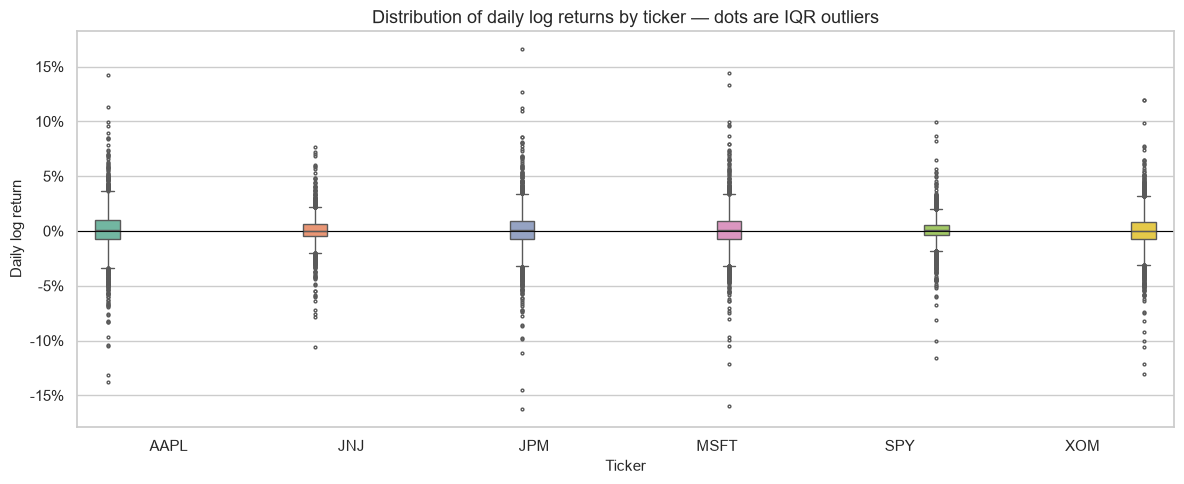

In [12]:
# Daily return distribution by ticker (continuous variable split by a categorical one)
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df.dropna(subset=['log_ret']), x='Ticker', y='log_ret', hue='Ticker',
            palette='Set2', fliersize=2, legend=False, ax=ax)
ax.axhline(0, color='black', lw=0.8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(title='Distribution of daily log returns by ticker — dots are IQR outliers',
       xlabel='Ticker', ylabel='Daily log return')
plt.tight_layout(); save_fig('03_returns_boxplot'); plt.show()

In [13]:
# z-score based outlier count per ticker
df['ret_z'] = df.groupby('Ticker', observed=True)['log_ret'].transform(lambda r: (r - r.mean()) / r.std())
outlier_summary = (df.assign(abs_z=df['ret_z'].abs())
                     .groupby('Ticker', observed=True)
                     .agg(days=('log_ret', 'count'),
                          z_gt_3=('abs_z', lambda z: (z > 3).sum()),
                          z_gt_5=('abs_z', lambda z: (z > 5).sum()),
                          max_abs_return=('log_ret', lambda r: r.abs().max())))
# Under a normal distribution only ~0.27% of days should exceed |z| > 3
outlier_summary['pct_z_gt_3'] = outlier_summary['z_gt_3'] / outlier_summary['days'] * 100
outlier_summary['expected_if_normal_%'] = 0.27
print('Possible data errors (|daily return| > 40%):', (df['log_ret'].abs() > np.log(1.4)).sum())
outlier_summary

Possible data errors (|daily return| > 40%): 0


,days,z_gt_3,z_gt_5,max_abs_return,pct_z_gt_3,expected_if_normal_%
Ticker,,,,,,
AAPL,4243,61,9,0.1426,1.4377,0.2700
JNJ,4243,60,18,0.1058,1.4141,0.2700
JPM,4243,60,11,0.1656,1.4141,0.2700
MSFT,4243,56,11,0.1595,1.3198,0.2700
SPY,4243,61,11,0.1159,1.4377,0.2700
XOM,4243,63,9,0.1304,1.4848,0.2700


In [14]:
# The ten most extreme days across the universe — do they line up with known market events?
(df.loc[df['ret_z'].abs().nlargest(10).index, ['Date', 'Ticker', 'log_ret', 'ret_z', 'VIXCLS']]
   .sort_values('Date')
   .assign(Date=lambda d: d['Date'].dt.strftime('%Y-%m-%d')))

,Date,Ticker,log_ret,ret_z,VIXCLS
6497,2018-12-14,JNJ,-0.1058,-9.8073,20.6500
11049,2020-03-09,JPM,-0.1456,-8.4854,41.9400
23781,2020-03-09,XOM,-0.1304,-8.2804,41.9400
19540,2020-03-12,SPY,-0.1006,-9.3856,53.9000
11053,2020-03-13,JPM,0.1656,9.5825,75.4700
19542,2020-03-16,SPY,-0.1159,-10.8078,57.8300
15298,2020-03-16,MSFT,-0.1595,-9.7559,57.8300
11054,2020-03-16,JPM,-0.1621,-9.4466,57.8300
20816,2025-04-09,SPY,0.0999,9.2250,52.3300
16899,2026-07-30,MSFT,0.1442,8.7350,20.6600


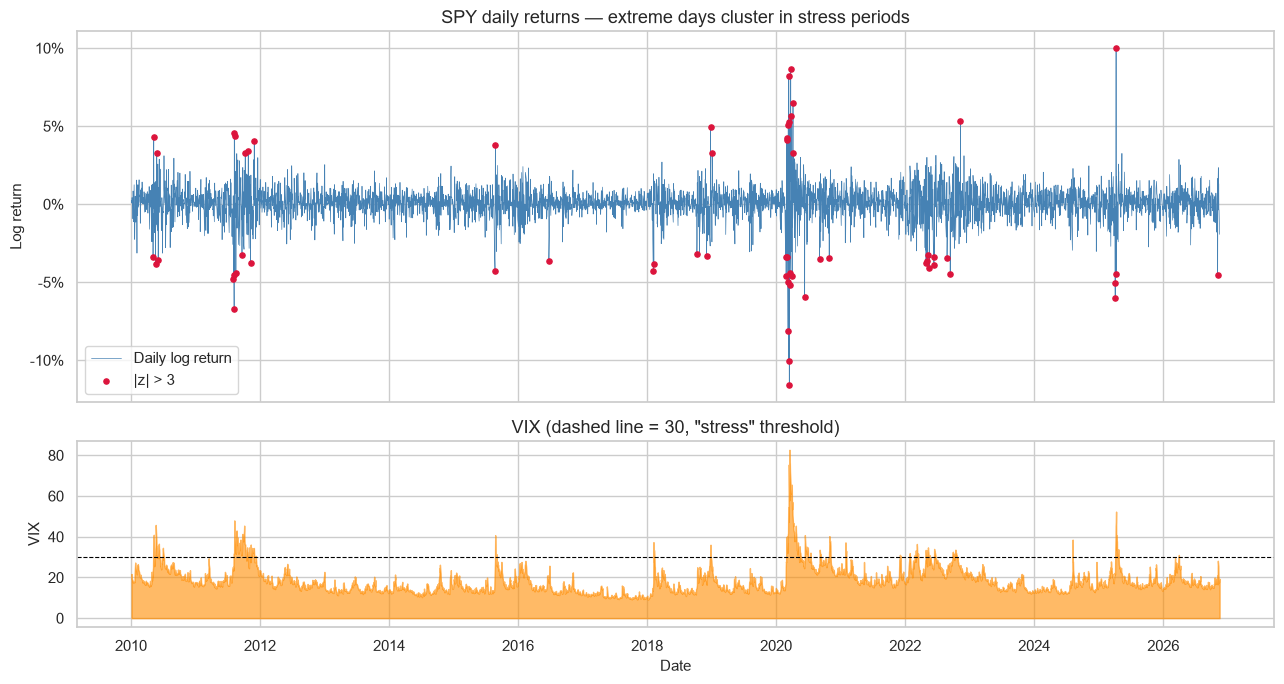

In [15]:
# Where the extremes cluster in time: SPY returns with |z| > 3 highlighted, VIX below
spy = df[df['Ticker'] == 'SPY'].set_index('Date')
extreme = spy[spy['ret_z'].abs() > 3]

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
axes[0].plot(spy.index, spy['log_ret'], lw=0.5, color='steelblue', label='Daily log return')
axes[0].scatter(extreme.index, extreme['log_ret'], color='crimson', s=14, zorder=3, label='|z| > 3')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[0].set(title='SPY daily returns — extreme days cluster in stress periods', ylabel='Log return')
axes[0].legend(loc='lower left')
axes[1].fill_between(spy.index, spy['VIXCLS'], color='darkorange', alpha=0.6)
axes[1].axhline(30, ls='--', color='black', lw=0.8)
axes[1].set(title='VIX (dashed line = 30, "stress" threshold)', ylabel='VIX', xlabel='Date')
plt.tight_layout(); save_fig('04_spy_outliers_vix'); plt.show()

In [16]:
# Volume spikes (IQR rule on the volume z-score)
q1, q3 = df['volume_z'].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
spike_share = (df['volume_z'] > upper_fence).mean() * 100
spike_ret = df.loc[df['volume_z'] > upper_fence, 'log_ret'].abs().mean()
normal_ret = df.loc[df['volume_z'] <= upper_fence, 'log_ret'].abs().mean()
print(f'Volume spikes (z above IQR fence {upper_fence:.2f}): {spike_share:.1f}% of days')
if spike_share > 0:
    print(f'Mean |return| on spike days: {spike_ret:.2%}  vs  other days: {normal_ret:.2%}')

Volume spikes (z above IQR fence 2.27): 4.3% of days
Mean |return| on spike days: 2.31%  vs  other days: 0.96%


**Outlier decision.** If the data-error check above reports no >40% moves, the adjusted prices are consistent and the
extreme days are real events. They are kept in the dataset. For the linear baseline, continuous features are
**winsorised at the 1st/99th percentile of the training period** (Section 7) so a handful of crash days cannot dominate
the coefficients; the target itself is not altered.

## 6. Exploratory Data Analysis

### 6.1 Price trends and drawdowns

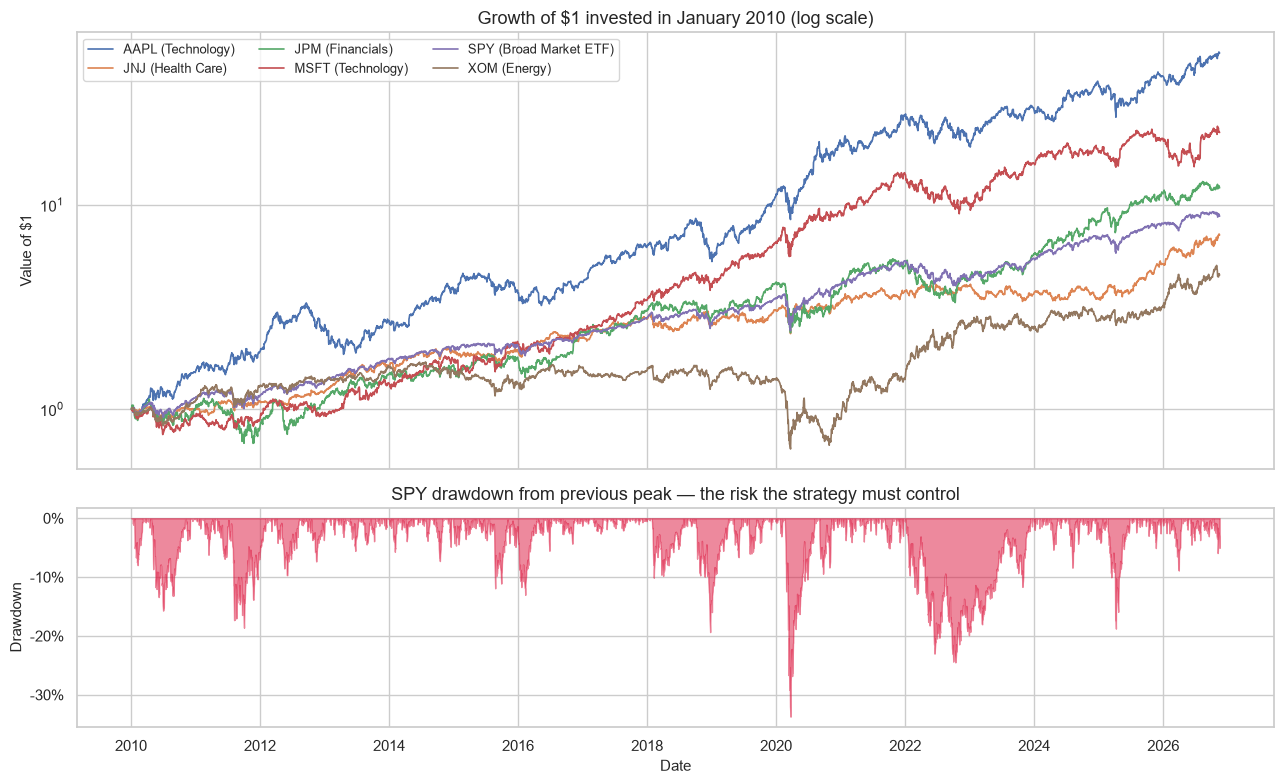

SPY maximum drawdown: -33.7% on 2020-03-23


In [17]:
wide_close = df.pivot(index='Date', columns='Ticker', values='Close')
growth = wide_close / wide_close.bfill().iloc[0]
spy_drawdown = wide_close['SPY'] / wide_close['SPY'].cummax() - 1

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for ticker in growth.columns:
    axes[0].plot(growth.index, growth[ticker], lw=1.2, label=f'{ticker} ({TICKERS[ticker]})')
axes[0].set_yscale('log')
axes[0].set(title='Growth of $1 invested in January 2010 (log scale)', ylabel='Value of $1')
axes[0].legend(ncol=3, fontsize=9)
axes[1].fill_between(spy_drawdown.index, spy_drawdown, 0, color='crimson', alpha=0.5)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[1].set(title='SPY drawdown from previous peak — the risk the strategy must control',
            ylabel='Drawdown', xlabel='Date')
plt.tight_layout(); save_fig('05_growth_and_drawdown'); plt.show()

print(f'SPY maximum drawdown: {spy_drawdown.min():.1%} on {spy_drawdown.idxmin():%Y-%m-%d}')

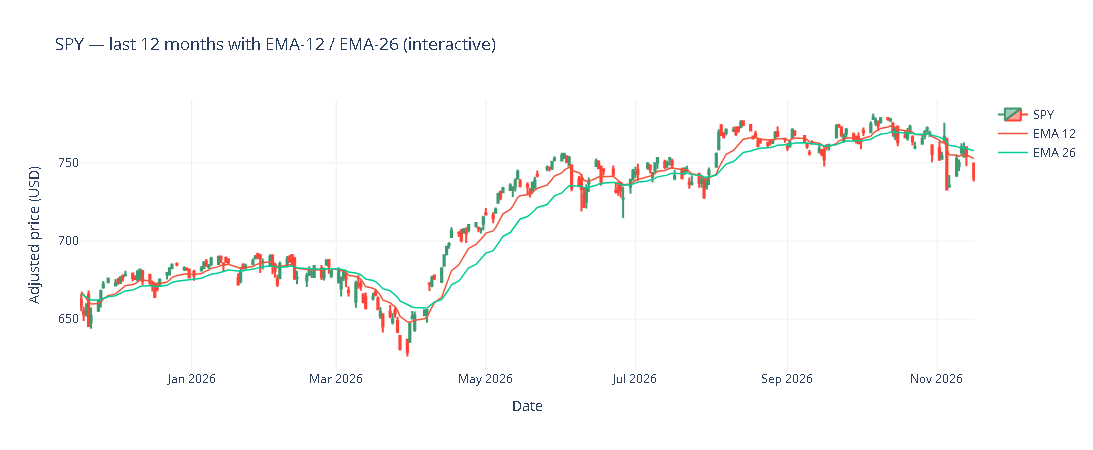

In [18]:
# Interactive view of the most recent year: candlesticks with the EMA trend features
recent = spy.loc[spy.index >= spy.index.max() - pd.DateOffset(years=1)]
fig = go.Figure([
    go.Candlestick(x=recent.index, open=recent['Open'], high=recent['High'],
                   low=recent['Low'], close=recent['Close'], name='SPY'),
    go.Scatter(x=recent.index, y=recent['ema_12'], name='EMA 12', line=dict(width=1.5)),
    go.Scatter(x=recent.index, y=recent['ema_26'], name='EMA 26', line=dict(width=1.5)),
])
fig.update_layout(title='SPY — last 12 months with EMA-12 / EMA-26 (interactive)',
                  xaxis_title='Date', yaxis_title='Adjusted price (USD)',
                  xaxis_rangeslider_visible=False, height=450, template='plotly_white')
fig.show()

### 6.2 Return distributions — fat tails

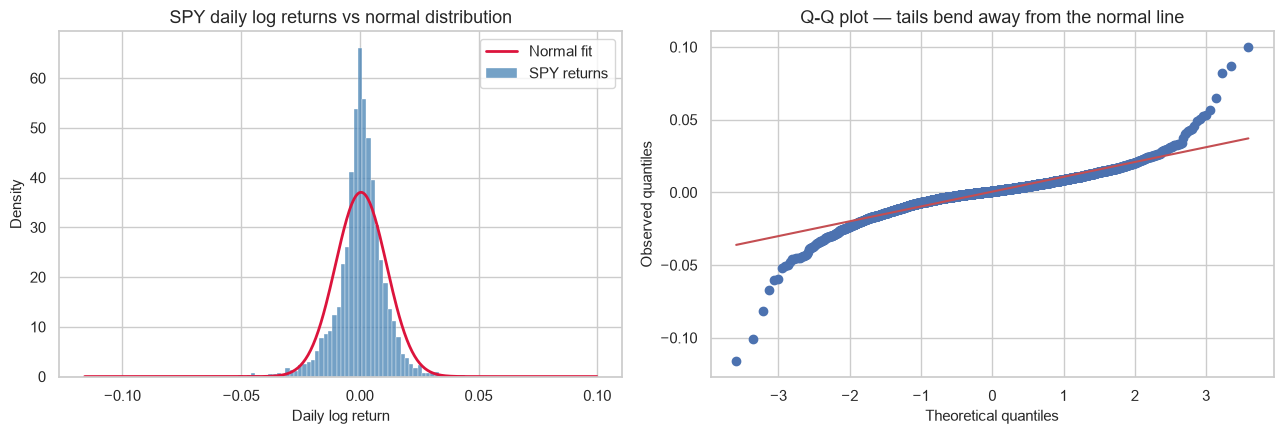

,ann_return,ann_vol,skew,excess_kurtosis,pct_up_days
Ticker,,,,,
AAPL,0.2382,0.2806,-0.1650,6.0375,53.0160
JNJ,0.1164,0.1720,-0.3103,8.5958,52.0971
JPM,0.1479,0.2734,-0.1161,9.4090,52.1442
MSFT,0.1850,0.2607,-0.0154,8.6719,52.2856
SPY,0.1290,0.1710,-0.5636,12.3414,55.1602
XOM,0.0896,0.2507,-0.2131,6.5849,50.9425


In [19]:
spy_ret = spy['log_ret'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(spy_ret, bins=120, stat='density', color='steelblue', ax=axes[0], label='SPY returns')
x = np.linspace(spy_ret.min(), spy_ret.max(), 400)
axes[0].plot(x, stats.norm.pdf(x, spy_ret.mean(), spy_ret.std()), color='crimson', lw=2, label='Normal fit')
axes[0].set(title='SPY daily log returns vs normal distribution', xlabel='Daily log return', ylabel='Density')
axes[0].legend()
stats.probplot(spy_ret, dist='norm', plot=axes[1])
axes[1].set(title='Q-Q plot — tails bend away from the normal line', xlabel='Theoretical quantiles',
            ylabel='Observed quantiles')
plt.tight_layout(); save_fig('06_return_distribution'); plt.show()

dist_stats = df.groupby('Ticker', observed=True)['log_ret'].agg(
    ann_return=lambda r: r.mean() * 252, ann_vol=lambda r: r.std() * np.sqrt(252),
    skew='skew', excess_kurtosis=lambda r: r.kurt(), pct_up_days=lambda r: (r > 0).mean() * 100)
dist_stats

### 6.3 Stationarity

The problem statement notes that prices are non-stationary. The Augmented Dickey-Fuller (ADF) test checks this:
p-value < 0.05 ⇒ reject the unit root ⇒ series is stationary. We test price levels against log returns.

In [20]:
adf_rows = []
for ticker, g in df.groupby('Ticker', observed=True):
    for col, label in [('Close', 'Price level'), ('log_ret', 'Log return')]:
        stat, pvalue, *_ = adfuller(g[col].dropna(), autolag='AIC')
        adf_rows.append({'Ticker': ticker, 'Series': label, 'ADF statistic': stat, 'p-value': pvalue,
                         'Stationary (p<0.05)': pvalue < 0.05})
adf_table = pd.DataFrame(adf_rows).pivot(index='Ticker', columns='Series', values=['p-value', 'Stationary (p<0.05)'])
adf_table

C:\Users\sbrit\AppData\Local\Temp\ipykernel_38544\2957613223.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, *_ = adfuller(g[col].dropna(), autolag='AIC')
C:\Users\sbrit\AppData\Local\Temp\ipykernel_38544\2957613223.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, *_ = adfuller(g[col].dropna(), autolag='AIC')
C:\Users\sbrit\AppData\Local

p-value             Stationary (p<0.05)            
Series Log return Price level          Log return Price level
Ticker                                                       
AAPL       0.0000      0.9991                True       False
JNJ        0.0000      0.9989                True       False
JPM        0.0000      0.9989                True       False
MSFT       0.0000      0.9898                True       False
SPY        0.0000      0.9985                True       False
XOM        0.0000      0.9978                True       False

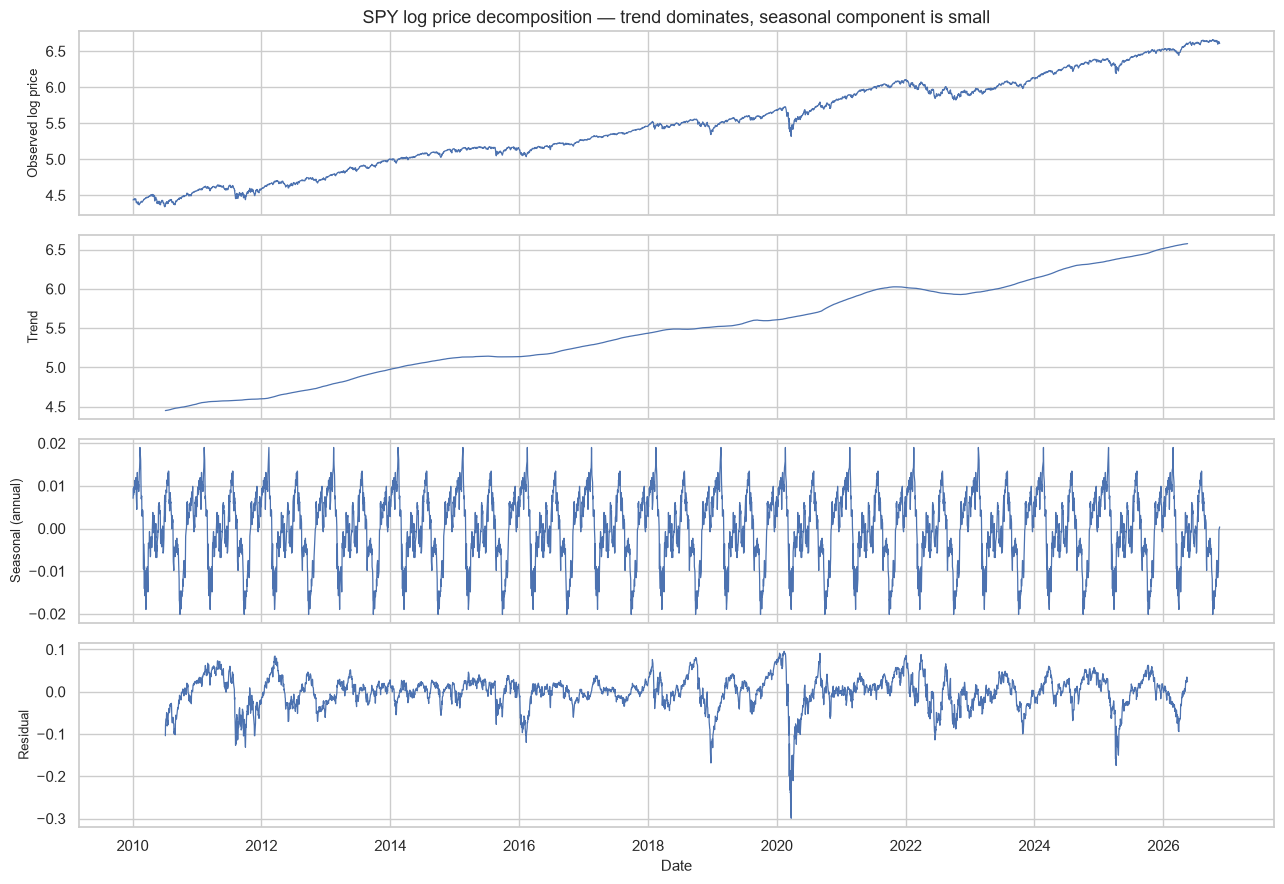

In [21]:
# Seasonal decomposition of SPY log price (252 trading days ~ one year)
decomp = seasonal_decompose(np.log(spy['Close']).dropna(), model='additive', period=252)
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, (series, title) in zip(axes, [(decomp.observed, 'Observed log price'), (decomp.trend, 'Trend'),
                                      (decomp.seasonal, 'Seasonal (annual)'), (decomp.resid, 'Residual')]):
    ax.plot(series, lw=0.9)
    ax.set_ylabel(title, fontsize=9)
axes[0].set_title('SPY log price decomposition — trend dominates, seasonal component is small')
axes[-1].set_xlabel('Date')
plt.tight_layout(); save_fig('07_seasonal_decomposition'); plt.show()

### 6.4 Autocorrelation and volatility clustering

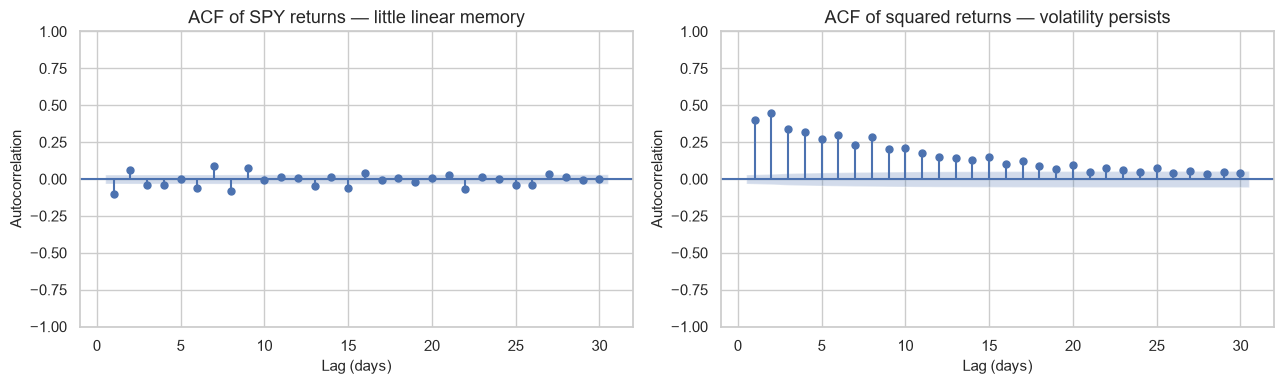

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(spy_ret, lags=30, ax=axes[0], zero=False)
axes[0].set(title='ACF of SPY returns — little linear memory', xlabel='Lag (days)', ylabel='Autocorrelation')
plot_acf(spy_ret ** 2, lags=30, ax=axes[1], zero=False)
axes[1].set(title='ACF of squared returns — volatility persists', xlabel='Lag (days)', ylabel='Autocorrelation')
plt.tight_layout(); save_fig('08_acf_returns'); plt.show()

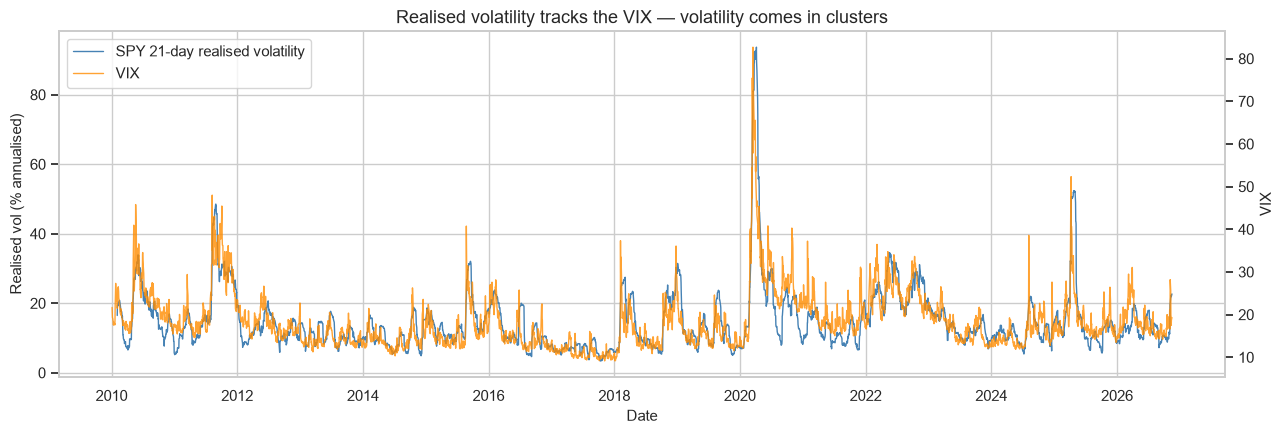

In [23]:
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.plot(spy.index, spy['vol_21d'] * 100, color='steelblue', lw=1, label='SPY 21-day realised volatility')
ax1.set(ylabel='Realised vol (% annualised)', xlabel='Date',
        title='Realised volatility tracks the VIX — volatility comes in clusters')
ax2 = ax1.twinx()
ax2.plot(spy.index, spy['VIXCLS'], color='darkorange', lw=1, alpha=0.8, label='VIX')
ax2.set_ylabel('VIX')
ax2.grid(False)
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc='upper left')
plt.tight_layout(); save_fig('09_vol_vs_vix'); plt.show()

### 6.5 Macroeconomic backdrop

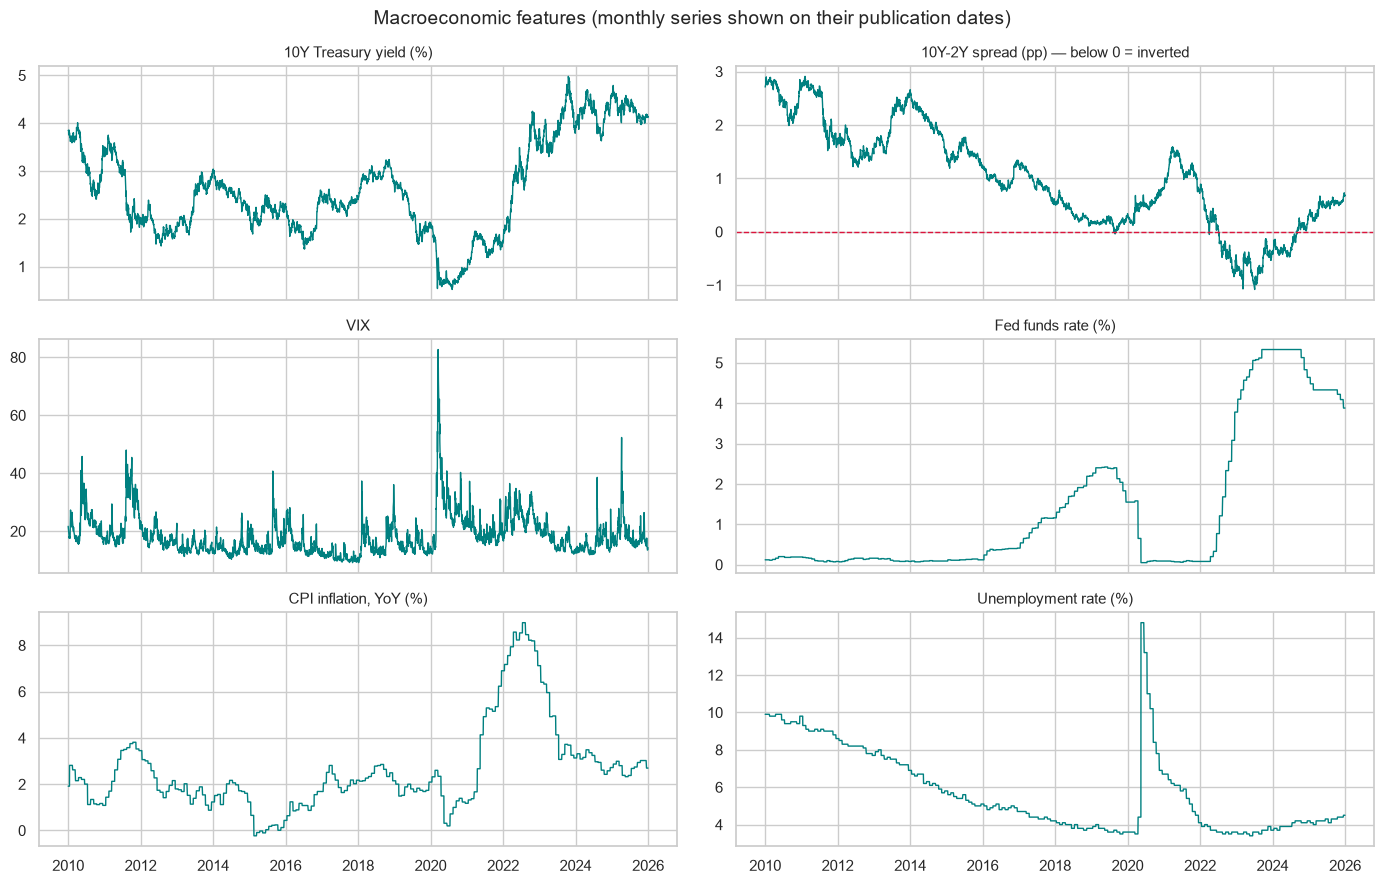

In [24]:
macro_plot = macro_daily.join(macro_monthly.set_index('Date')[['FEDFUNDS', 'CPI_YoY', 'UNRATE']], how='outer').ffill()
macro_plot = macro_plot.loc[PRICE_START:PRICE_END]
panels = [('DGS10', '10Y Treasury yield (%)'), ('T10Y2Y', '10Y-2Y spread (pp) — below 0 = inverted'),
          ('VIXCLS', 'VIX'), ('FEDFUNDS', 'Fed funds rate (%)'),
          ('CPI_YoY', 'CPI inflation, YoY (%)'), ('UNRATE', 'Unemployment rate (%)')]
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for ax, (col, title) in zip(axes.flat, panels):
    ax.plot(macro_plot.index, macro_plot[col], lw=1, color='teal')
    if col == 'T10Y2Y':
        ax.axhline(0, color='crimson', ls='--', lw=1)
    ax.set_title(title, fontsize=11)
fig.suptitle('Macroeconomic features (monthly series shown on their publication dates)', fontsize=14)
plt.tight_layout(); save_fig('10_macro_panel'); plt.show()

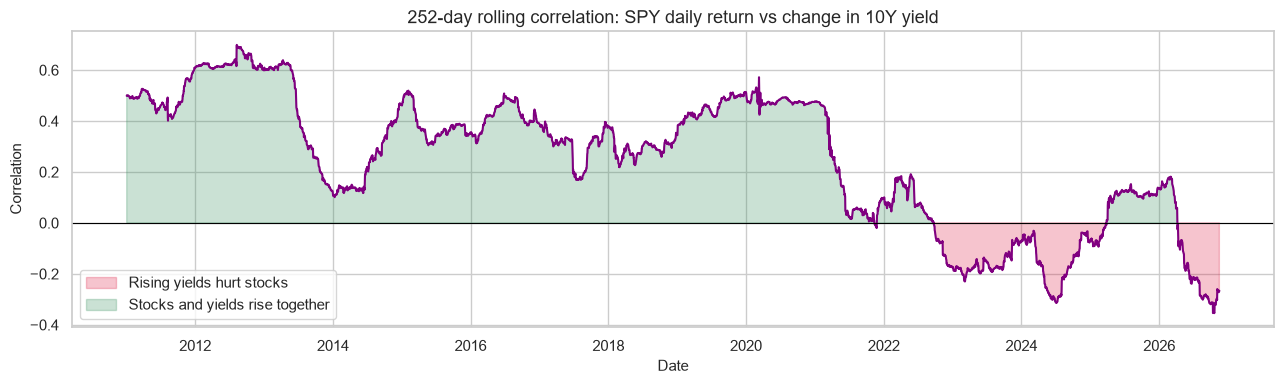

In [25]:
# Rolling 1-year correlation between SPY returns and changes in the 10Y yield.
# A sign flip means the macro relationship is regime-dependent — a key challenge for a static model.
# This chart compares SAME-day stock and yield moves (descriptive, not predictive)
same_day_yield_chg = macro_daily['DGS10_chg'].copy()
same_day_yield_chg.index = same_day_yield_chg.index - pd.offsets.BDay(1)
roll_corr = spy['log_ret'].rolling(252).corr(same_day_yield_chg.reindex(spy.index))
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(roll_corr.index, roll_corr, color='purple')
ax.axhline(0, color='black', lw=0.8)
ax.fill_between(roll_corr.index, roll_corr, 0, where=roll_corr < 0, color='crimson', alpha=0.25,
                label='Rising yields hurt stocks')
ax.fill_between(roll_corr.index, roll_corr, 0, where=roll_corr > 0, color='seagreen', alpha=0.25,
                label='Stocks and yields rise together')
ax.set(title='252-day rolling correlation: SPY daily return vs change in 10Y yield',
       ylabel='Correlation', xlabel='Date')
ax.legend(loc='lower left')
plt.tight_layout(); save_fig('11_rolling_corr_yields'); plt.show()

### 6.6 Feature relationships with the target

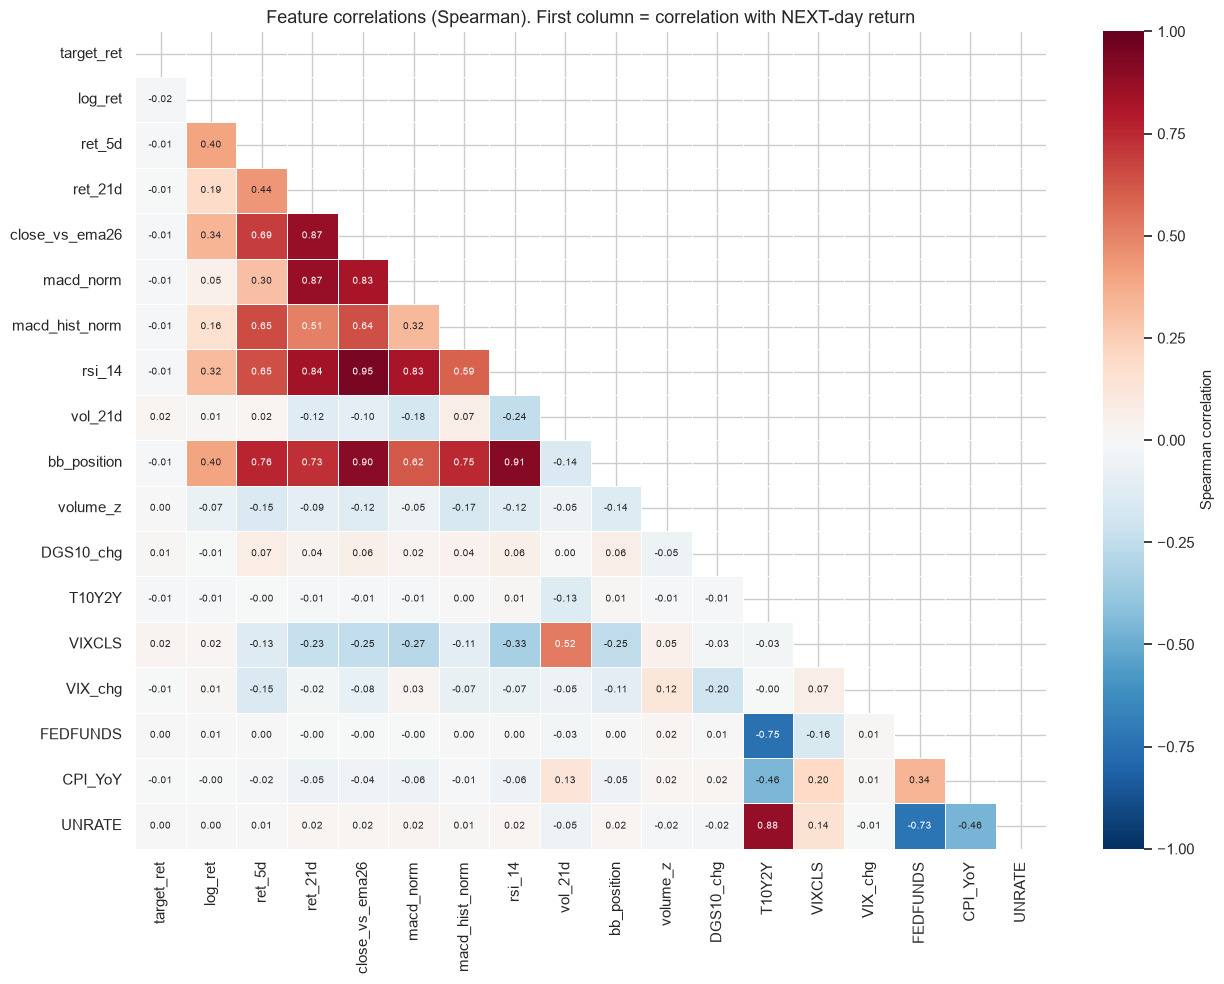

Strongest correlations with next-day return:
VIXCLS    0.0236
log_ret   0.0205
vol_21d   0.0164
rsi_14    0.0147
ret_5d    0.0137


In [26]:
corr_cols = ['target_ret', 'log_ret', 'ret_5d', 'ret_21d', 'close_vs_ema26', 'macd_norm', 'macd_hist_norm',
             'rsi_14', 'vol_21d', 'bb_position', 'volume_z', 'DGS10_chg', 'T10Y2Y', 'VIXCLS', 'VIX_chg',
             'FEDFUNDS', 'CPI_YoY', 'UNRATE']
corr = model_df[corr_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5, cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title('Feature correlations (Spearman). First column = correlation with NEXT-day return')
plt.tight_layout(); save_fig('12_correlation_heatmap'); plt.show()

print('Strongest correlations with next-day return:')
print(corr['target_ret'].drop('target_ret').abs().sort_values(ascending=False).head(5).round(4).to_string())

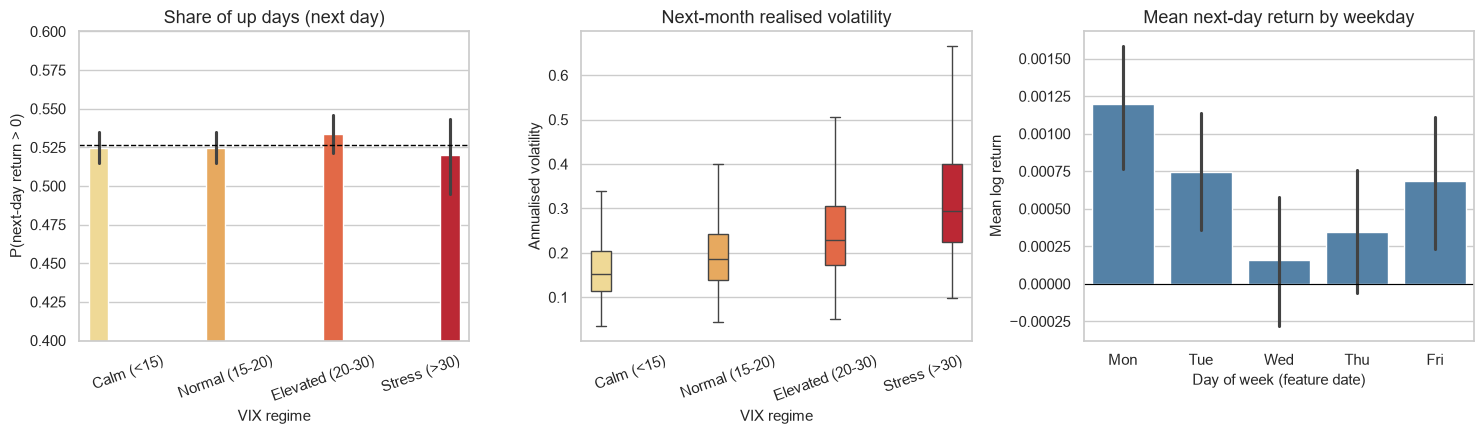

,days,up_rate,mean_next_ret_bps,next_ret_std_bps
vix_regime,,,,
Calm (<15),8718,0.5248,5.1347,104.2729
Normal (15-20),9264,0.5244,4.5332,132.1709
Elevated (20-30),5586,0.5337,7.0055,176.1888
Stress (>30),1536,0.5202,18.7986,302.5670


In [27]:
# Categorical views: does the market regime change next-day returns and future risk?
regime_stats = (model_df.groupby('vix_regime', observed=True)
                .agg(days=('target_ret', 'size'), up_rate=('target_up', 'mean'),
                     mean_next_ret_bps=('target_ret', lambda r: r.mean() * 1e4),
                     next_ret_std_bps=('target_ret', lambda r: r.std() * 1e4)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.barplot(data=model_df, x='vix_regime', y='target_up', hue='vix_regime', palette='YlOrRd', legend=False,
            errorbar=('ci', 95), ax=axes[0])
axes[0].axhline(model_df['target_up'].mean(), color='black', ls='--', lw=1)
axes[0].set(title='Share of up days (next day)', xlabel='VIX regime', ylabel='P(next-day return > 0)', ylim=(0.4, 0.6))
sns.boxplot(data=model_df, x='vix_regime', y='fwd_vol_21d', hue='vix_regime', palette='YlOrRd', legend=False,
            showfliers=False, ax=axes[1])
axes[1].set(title='Next-month realised volatility', xlabel='VIX regime', ylabel='Annualised volatility')
sns.barplot(data=model_df, x='day_of_week', y='target_ret', order=['Mon', 'Tue', 'Wed', 'Thu', 'Fri'],
            color='steelblue', errorbar=('ci', 95), ax=axes[2])
axes[2].axhline(0, color='black', lw=0.8)
axes[2].set(title='Mean next-day return by weekday', xlabel='Day of week (feature date)', ylabel='Mean log return')
for ax in axes[:2]:
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); save_fig('13_regime_categorical'); plt.show()
regime_stats

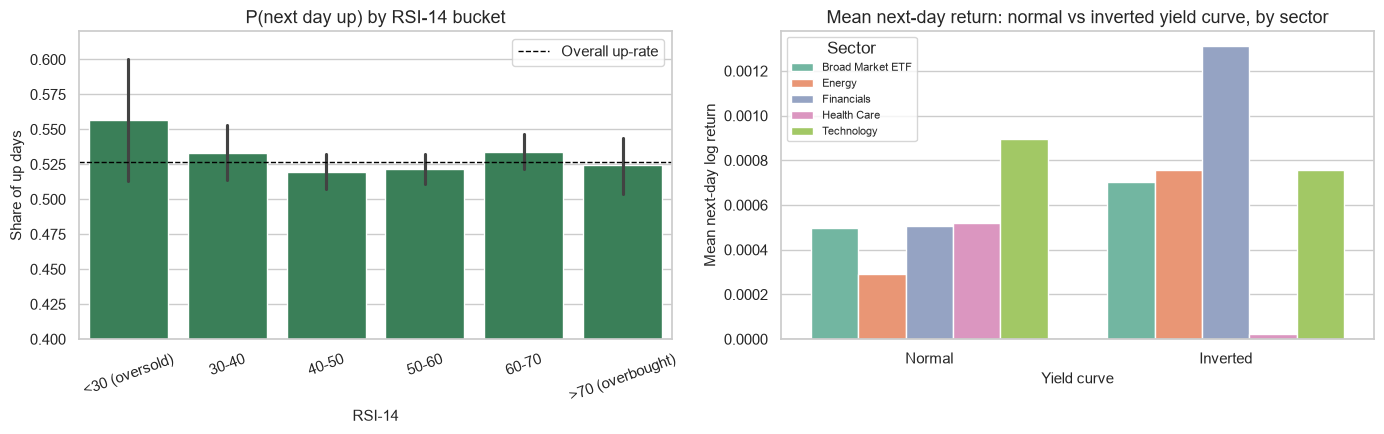

In [28]:
# Momentum indicator vs outcome: does RSI carry information about tomorrow?
model_df['rsi_bucket'] = pd.cut(model_df['rsi_14'], bins=[0, 30, 40, 50, 60, 70, 100],
                                labels=['<30 (oversold)', '30-40', '40-50', '50-60', '60-70', '>70 (overbought)'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=model_df, x='rsi_bucket', y='target_up', color='seagreen', errorbar=('ci', 95), ax=axes[0])
axes[0].axhline(model_df['target_up'].mean(), color='black', ls='--', lw=1, label='Overall up-rate')
axes[0].set(title='P(next day up) by RSI-14 bucket', xlabel='RSI-14', ylabel='Share of up days', ylim=(0.4, 0.62))
axes[0].legend(); axes[0].tick_params(axis='x', rotation=20)
sns.barplot(data=model_df, x='curve_inverted', y='target_ret', hue='Sector', errorbar=None, palette='Set2', ax=axes[1])
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set(title='Mean next-day return: normal vs inverted yield curve, by sector',
            xlabel='Yield curve', ylabel='Mean next-day log return')
axes[1].legend(fontsize=8, title='Sector')
plt.tight_layout(); save_fig('14_rsi_and_curve'); plt.show()

## 7. Baseline Model — Next-Day Direction Classification

**Task.** Binary classification: will tomorrow's return be positive (`target_up = 1`)?

**Validation design.** Time-series data must never be shuffled. The model is trained on **2010-2021** and tested on
**2022 onwards** (a period that includes the 2022 bear market and rate-hiking cycle, i.e. a genuine regime change).
A 5-day embargo is removed from the end of training so that no target overlaps the test window. Hyper-parameters are
tuned with TimeSeriesSplit (expanding window), not K-fold.

**Models.**
1. *Naive baseline* — always predict the majority class ("up"). Any model must beat this.
2. *Logistic regression* — scaled numeric features + one-hot ticker/weekday; regularisation strength `C` tuned by CV.

**Evaluation metrics and rationale.**
* **Directional accuracy** (= accuracy on the up/down label) is the metric named in the problem statement
  (target: > 55%). The share of days on which the sign was called correctly.
* Up days are ~53% of the sample, so accuracy alone flatters a model that always says "up". **Balanced accuracy**
  (mean of recall on up and down days) and **ROC-AUC** (ranking quality, independent of the 0.5 threshold) show
  whether the model has real skill. AUC = 0.5 means no skill.
* Because the end goal is trading, the predictions are also converted into a **long/flat strategy** and judged by
  **Sharpe ratio** and **maximum drawdown**, the two quantities the research question cares about.

In [29]:
train_mask = model_df['Date'] < SPLIT_DATE
embargo_start = model_df.loc[train_mask, 'Date'].drop_duplicates().nlargest(5).min()
train = model_df[train_mask & (model_df['Date'] < embargo_start)].sort_values('Date')
test = model_df[~train_mask].sort_values(['Ticker', 'Date'])

# Winsorise continuous features using training-period percentiles only (no test information)
lower, upper = train[NUMERIC_FEATURES].quantile(0.01), train[NUMERIC_FEATURES].quantile(0.99)
def winsorise(frame):
    out = frame.copy()
    out[NUMERIC_FEATURES] = out[NUMERIC_FEATURES].clip(lower, upper, axis=1)
    return out
X_train, y_train = winsorise(train)[NUMERIC_FEATURES + CATEGORICAL_FEATURES], train['target_up']
X_test, y_test = winsorise(test)[NUMERIC_FEATURES + CATEGORICAL_FEATURES], test['target_up']

print(f'Train: {train.Date.min():%Y-%m-%d} to {train.Date.max():%Y-%m-%d}  ({len(train):,} rows, '
      f'{y_train.mean():.1%} up days)')
print(f'Test : {test.Date.min():%Y-%m-%d} to {test.Date.max():%Y-%m-%d}  ({len(test):,} rows, '
      f'{y_test.mean():.1%} up days)')

Train: 2010-02-03 to 2021-12-23  (17,970 rows, 52.5% up days)
Test : 2022-01-03 to 2026-11-13  (7,104 rows, 53.0% up days)


In [30]:
# 1) Naive baseline: always predict the most frequent class in training
naive = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

# 2) Logistic regression with preprocessing in a single pipeline (prevents leakage across CV folds)
preprocess = ColumnTransformer([
    ('num', StandardScaler(), NUMERIC_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), CATEGORICAL_FEATURES),
])
logit_pipe = Pipeline([('prep', preprocess),
                       ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
search = GridSearchCV(logit_pipe, param_grid={'clf__C': [0.001, 0.01, 0.1, 1.0]},
                      cv=TimeSeriesSplit(n_splits=5), scoring='roc_auc', n_jobs=-1)
search.fit(X_train, y_train)
logit = search.best_estimator_
print(f"Best C = {search.best_params_['clf__C']}  |  mean CV ROC-AUC = {search.best_score_:.4f}")

Best C = 0.01  |  mean CV ROC-AUC = 0.5028


In [31]:
def evaluate(model, X, y, name):
    """Classification metrics for a fitted model."""
    proba = model.predict_proba(X)[:, 1]
    pred = (proba > 0.5).astype(int)
    return {'Model': name,
            'Directional accuracy': accuracy_score(y, pred),
            'Balanced accuracy': balanced_accuracy_score(y, pred),
            'ROC-AUC': roc_auc_score(y, proba) if len(np.unique(proba)) > 1 else 0.5,
            'Predicted up %': pred.mean() * 100}

metrics = pd.DataFrame([evaluate(naive, X_train, y_train, 'Naive (train)'),
                        evaluate(logit, X_train, y_train, 'Logistic (train)'),
                        evaluate(naive, X_test, y_test, 'Naive (test)'),
                        evaluate(logit, X_test, y_test, 'Logistic (test)')]).set_index('Model')
metrics.to_csv(RESULTS_DIR / 'baseline_classification_metrics.csv')
metrics

,Directional accuracy,Balanced accuracy,ROC-AUC,Predicted up %
Model,,,,
Naive (train),0.5249,0.5000,0.5000,100.0000
Logistic (train),0.5344,0.5196,0.5366,79.8497
Naive (test),0.5304,0.5000,0.5000,100.0000
Logistic (test),0.5156,0.4979,0.4964,79.1526


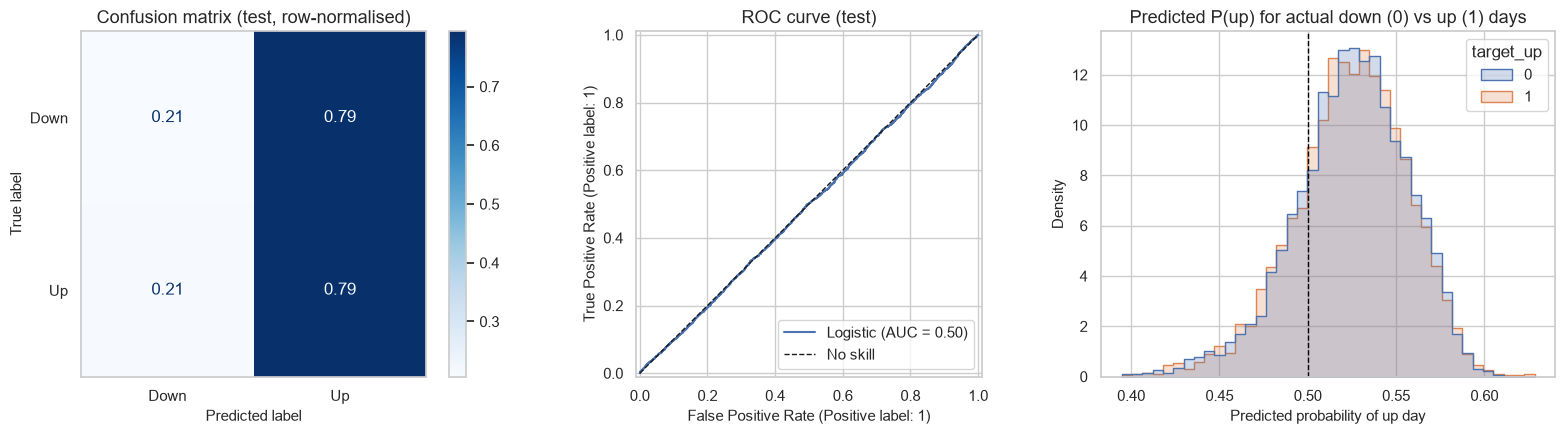

,Directional accuracy,Always-up accuracy,ROC-AUC
Ticker,,,
AAPL,0.5084,0.5287,0.4959
JNJ,0.5076,0.5152,0.4780
JPM,0.5600,0.5481,0.5254
MSFT,0.5220,0.5169,0.5023
SPY,0.5346,0.5329,0.4948
XOM,0.4611,0.5405,0.4767


In [32]:
test = test.assign(proba_up=logit.predict_proba(X_test)[:, 1])
test['pred_up'] = (test['proba_up'] > 0.5).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test['pred_up'], display_labels=['Down', 'Up'],
                                        cmap='Blues', normalize='true', values_format='.2f', ax=axes[0])
axes[0].set_title('Confusion matrix (test, row-normalised)'); axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, test['proba_up'], name='Logistic', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='No skill')
axes[1].set_title('ROC curve (test)'); axes[1].legend(loc='lower right')
sns.histplot(data=test, x='proba_up', hue='target_up', bins=40, element='step', stat='density',
             common_norm=False, ax=axes[2])
axes[2].axvline(0.5, color='black', ls='--', lw=1)
axes[2].set(title='Predicted P(up) for actual down (0) vs up (1) days', xlabel='Predicted probability of up day',
            ylabel='Density')
plt.tight_layout(); save_fig('15_model_diagnostics'); plt.show()

per_ticker = (test.groupby('Ticker', observed=True)
                  .apply(lambda g: pd.Series({'Directional accuracy': accuracy_score(g['target_up'], g['pred_up']),
                                              'Always-up accuracy': g['target_up'].mean(),
                                              'ROC-AUC': roc_auc_score(g['target_up'], g['proba_up'])})))
per_ticker

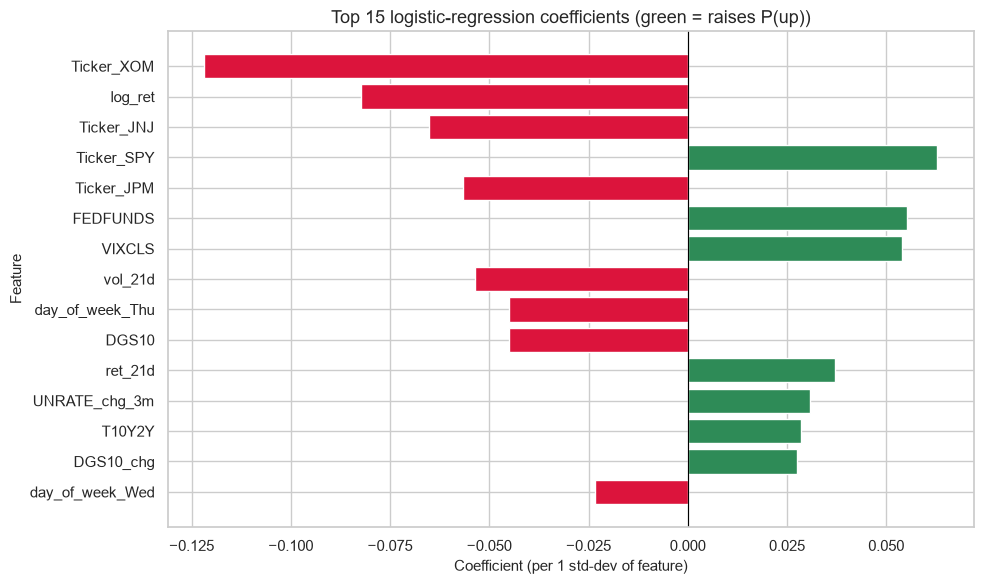

In [33]:
# Which features does the model lean on? (standardised coefficients, so magnitudes are comparable)
feature_names = logit.named_steps['prep'].get_feature_names_out()
coefs = (pd.Series(logit.named_steps['clf'].coef_[0], index=feature_names)
           .rename(lambda s: s.replace('num__', '').replace('cat__', '')))
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, 'seagreen', 'crimson'))
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Top 15 logistic-regression coefficients (green = raises P(up))',
       xlabel='Coefficient (per 1 std-dev of feature)', ylabel='Feature')
plt.tight_layout(); save_fig('16_coefficients'); plt.show()

### 7.1 Economic evaluation — does the signal help avoid drawdowns?

Each day, for each ticker, the strategy is **long** if the model's P(up) > 0.5 and **flat (cash)** otherwise.
Each position change costs 5 bps. The six tickers are equally weighted and compared with buy-and-hold over the
same test period. This is a deliberately simple stand-in for the reinforcement-learning execution agent planned for
final submission.

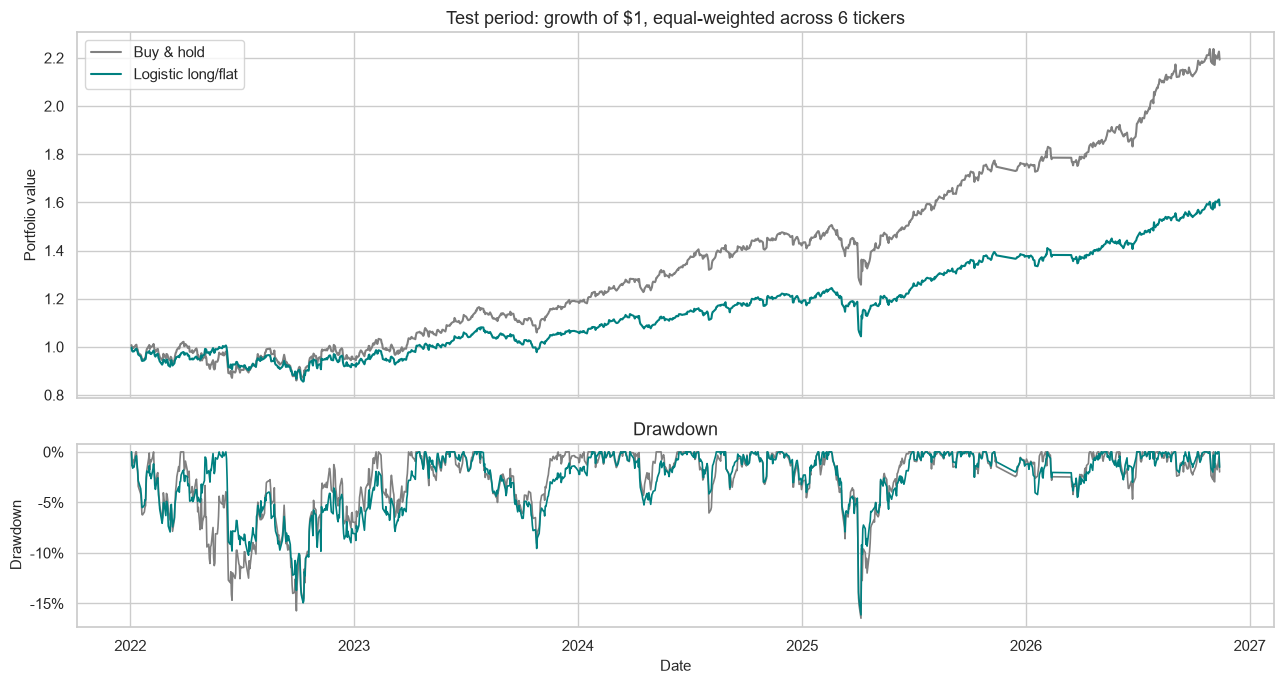

,CAGR,Ann. volatility,Sharpe,Max drawdown,Time in market
Strategy,,,,,
Buy & hold (equal weight),18.2%,15.6%,1.15,-16.5%,100%
Logistic long/flat (5 bps costs),10.3%,13.3%,0.81,-16.1%,79%


In [34]:
def performance(daily_returns, name):
    """Annualised return, volatility, Sharpe (rf = 0) and maximum drawdown from daily simple returns."""
    equity = (1 + daily_returns).cumprod()
    years = len(daily_returns) / 252
    return {'Strategy': name,
            'CAGR': equity.iloc[-1] ** (1 / years) - 1,
            'Ann. volatility': daily_returns.std() * np.sqrt(252),
            'Sharpe': daily_returns.mean() / daily_returns.std() * np.sqrt(252),
            'Max drawdown': (equity / equity.cummax() - 1).min(),
            'Time in market': np.nan}

bt = test[['Date', 'Ticker', 'target_ret', 'pred_up']].copy()
bt['next_simple_ret'] = np.expm1(bt['target_ret'])                       # return earned by holding into tomorrow
bt['trade'] = bt.groupby('Ticker', observed=True)['pred_up'].diff().abs().fillna(bt['pred_up'])
bt['strategy_ret'] = bt['pred_up'] * bt['next_simple_ret'] - bt['trade'] * TRANSACTION_COST

portfolio = bt.groupby('Date')[['next_simple_ret', 'strategy_ret']].mean()   # equal weight across tickers
perf = pd.DataFrame([performance(portfolio['next_simple_ret'], 'Buy & hold (equal weight)'),
                     performance(portfolio['strategy_ret'], 'Logistic long/flat (5 bps costs)')]).set_index('Strategy')
perf.loc['Buy & hold (equal weight)', 'Time in market'] = 1.0
perf.loc['Logistic long/flat (5 bps costs)', 'Time in market'] = bt['pred_up'].mean()
perf.to_csv(RESULTS_DIR / 'baseline_backtest_metrics.csv')

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for col, label, color in [('next_simple_ret', 'Buy & hold', 'grey'), ('strategy_ret', 'Logistic long/flat', 'teal')]:
    equity = (1 + portfolio[col]).cumprod()
    axes[0].plot(equity.index, equity, label=label, color=color, lw=1.5)
    axes[1].plot(equity.index, equity / equity.cummax() - 1, label=label, color=color, lw=1.2)
axes[0].set(title='Test period: growth of $1, equal-weighted across 6 tickers', ylabel='Portfolio value')
axes[0].legend()
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[1].set(title='Drawdown', ylabel='Drawdown', xlabel='Date')
plt.tight_layout(); save_fig('17_backtest'); plt.show()

perf.style.format({'CAGR': '{:.1%}', 'Ann. volatility': '{:.1%}', 'Sharpe': '{:.2f}',
                   'Max drawdown': '{:.1%}', 'Time in market': '{:.0%}'})

In [35]:
# Summary
test_row = metrics.loc['Logistic (test)']
naive_row = metrics.loc['Naive (test)']
print(f"Directional accuracy (test): logistic {test_row['Directional accuracy']:.1%} vs naive {naive_row['Directional accuracy']:.1%} "
      f"(project target > 55%: {'MET' if test_row['Directional accuracy'] > 0.55 else 'NOT MET'})")
print(f"Balanced accuracy {test_row['Balanced accuracy']:.3f} | ROC-AUC {test_row['ROC-AUC']:.3f}")
bh, strat = perf.loc['Buy & hold (equal weight)'], perf.loc['Logistic long/flat (5 bps costs)']
print(f"Sharpe {strat['Sharpe']:.2f} vs {bh['Sharpe']:.2f} buy & hold | "
      f"max drawdown {strat['Max drawdown']:.1%} vs {bh['Max drawdown']:.1%}")

Directional accuracy (test): logistic 51.6% vs naive 53.0% (project target > 55%: NOT MET)
Balanced accuracy 0.498 | ROC-AUC 0.496
Sharpe 0.81 vs 1.15 buy & hold | max drawdown -16.1% vs -16.5%


## 8. Findings and Next Steps

**What the data shows (EDA)**
* **Prices are non-stationary; returns are stationary.** ADF tests fail to reject a unit root for price levels but
  reject it strongly for log returns. Models therefore use returns and scale-free indicators, not raw prices.
* **Returns are fat-tailed.** Excess kurtosis is well above 0 and far more days exceed |z| > 3 than a normal
  distribution allows. The extreme days are real events (they line up with VIX spikes), not data errors, and were kept.
* **Little linear memory in returns, strong memory in volatility.** The ACF of returns is near zero while the ACF of
  squared returns is large and slow to decay. Risk is more predictable than direction — useful for position sizing
  and drawdown control.
* **Regimes matter.** High-VIX regimes have much higher next-month volatility, and the stock/yield correlation
  changes sign over time. A single static model will struggle; this motivates the TFT's variable-selection network and
  regime-aware features.
* **Individual features have weak correlation with next-day returns** — typical of liquid markets and the core
  difficulty of the research question.

**Baseline model** — The logistic-regression baseline shows no predictive skill on the 2022+ test period. Directional accuracy (51.6%) is below the naive “always up” baseline (53.0%) and the 55% target, and balanced accuracy (0.498) and ROC-AUC (0.496) are at the no-skill value of 0.5. The long/flat strategy built on its signals roughly halved the annual return (10.3% vs 18.2%) and lowered the Sharpe ratio (0.81 vs 1.15) without reducing maximum drawdown (−16.1% vs −16.5%). Its in/out decisions were effectively random: it missed rallies as often as it avoided declines. This matches the EDA, which found near-zero autocorrelation in daily returns, weak feature–return correlations, and a regime change around 2022 that a linear model trained on 2010–2021 cannot adapt to. The EDA also found that volatility is strongly persistent, so final submission will shift focus from predicting daily direction to forecasting risk for position sizing and drawdown control, using longer horizons, non-linear and regime-aware models (gradient boosting, TFT), news sentiment, and walk-forward retraining.

**Next steps (Final Capstone)**
1. Add FinBERT sentiment scores from financial news headlines.
2. Walk-forward (rolling-origin) evaluation instead of a single split.
3. Non-linear models (gradient boosting) and the Temporal Fusion Transformer with multi-horizon quantile forecasts.
4. Volatility-targeted position sizing and portfolio-level drawdown limits; then the RL execution agent.